In [1]:
print("Retail Sales Data Analysis - BDA Project")
print("BE 7th Semester")
print("Python is working successfully!")

Retail Sales Data Analysis - BDA Project
BE 7th Semester
Python is working successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1200

categories = ["Electronics", "Clothing", "Home & Kitchen", "Books", "Sports"]
products = {
    "Electronics": ["Headphones", "Keyboard", "Smartwatch", "Speaker"],
    "Clothing": ["T-shirt", "Jeans", "Jacket", "Sneakers"],
    "Home & Kitchen": ["Mixer", "Cookware", "Bedsheet", "Lamp"],
    "Books": ["Fiction Book", "Textbook", "Notebook", "Biography"],
    "Sports": ["Yoga Mat", "Football", "Dumbbells", "Badminton Set"]
}

category = np.random.choice(categories, n)
product = [np.random.choice(products[c]) for c in category]

price_ranges = {
    "Electronics": (700, 9000),
    "Clothing": (300, 3500),
    "Home & Kitchen": (250, 6000),
    "Books": (100, 1200),
    "Sports": (250, 4500)
}

price = [round(np.random.uniform(*price_ranges[c]), 2)
         for c in category]

quantity = np.random.randint(1, 6, n)
discount = np.random.choice(
    [0, 0.05, 0.10, 0.15, 0.20], n
)

df = pd.DataFrame({
    "Order_ID": [f"ORD{i:05d}" for i in range(1, n + 1)],
    "Category": category,
    "Product": product,
    "Quantity": quantity,
    "Unit_Price": price,
    "Discount": discount,
    "Region": np.random.choice(
        ["North", "South", "East", "West"], n
    ),
    "Order_Date": np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"), n
    )
})

df["Revenue"] = (
    df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])
).round(2)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset created successfully!
Dataset shape: (1200, 9)


,Order_ID,Category,Product,Quantity,Unit_Price,Discount,Region,Order_Date,Revenue
0,ORD00001,Books,Textbook,1,292.25,0.00,West,2025-09-19,292.25
1,ORD00002,Sports,Badminton Set,1,1783.28,0.05,South,2025-11-09,1694.12
2,ORD00003,Home & Kitchen,Cookware,2,5458.87,0.10,South,2025-03-12,9825.97
3,ORD00004,Sports,Badminton Set,2,3522.26,0.05,West,2025-08-07,6692.29
4,ORD00005,Sports,Football,1,2615.71,0.05,North,2025-01-21,2484.92


In [4]:
# 1. Display the dataset dimensions
print("Dataset dimensions:", df.shape)

# 2. Display column names and data types
print("\nDataset information:")
df.info()

# 3. Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 4. Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 5. Generate statistical summary
print("\nStatistical summary:")
display(df.describe())

Dataset dimensions: (1200, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    1200 non-null   object        
 1   Category    1200 non-null   object        
 2   Product     1200 non-null   object        
 3   Quantity    1200 non-null   int64         
 4   Unit_Price  1200 non-null   float64       
 5   Discount    1200 non-null   float64       
 6   Region      1200 non-null   object        
 7   Order_Date  1200 non-null   datetime64[ns]
 8   Revenue     1200 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 84.5+ KB

Missing values in each column:
Order_ID      0
Category      0
Product       0
Quantity      0
Unit_Price    0
Discount      0
Region        0
Order_Date    0
Revenue       0
dtype: int64

Number of duplicate rows: 0

Statistical s

,Quantity,Unit_Price,Discount,Order_Date,Revenue
count,1200.000000,1200.000000,1200.000000,1200,1200.000000
mean,2.995000,2602.203933,0.102792,2025-06-27 14:49:11.999999744,6924.310583
min,1.000000,102.310000,0.000000,2025-01-01 00:00:00,89.180000
25%,2.000000,932.502500,0.050000,2025-03-28 00:00:00,2057.522500
50%,3.000000,2135.105000,0.100000,2025-06-28 00:00:00,4533.060000
75%,4.000000,3732.407500,0.150000,2025-09-28 00:00:00,9742.907500
max,5.000000,8957.320000,0.200000,2025-12-31 00:00:00,44221.300000
std,1.418915,2053.339608,0.070078,NaN,6897.854457


In [5]:
# Convert order dates to datetime format
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Remove invalid quantities and prices
df = df[
    (df["Quantity"] > 0) &
    (df["Unit_Price"] > 0) &
    (df["Revenue"] >= 0)
]

print("Data cleaning completed!")
print("Rows after cleaning:", len(df))
print("Missing values remaining:", df.isnull().sum().sum())

Data cleaning completed!
Rows after cleaning: 1200
Missing values remaining: 0


In [6]:
total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()
average_revenue = df["Revenue"].mean()

print("===== RETAIL SALES ANALYSIS =====")
print(f"Total Revenue: Rs. {total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Units Sold: {total_units}")
print(f"Average Revenue per Transaction: Rs. {average_revenue:,.2f}")

===== RETAIL SALES ANALYSIS =====
Total Revenue: Rs. 8,309,172.70
Total Orders: 1200
Total Units Sold: 3594
Average Revenue per Transaction: Rs. 6,924.31


Revenue by Product Category:


,Category,Revenue
0,Electronics,3304263.64
1,Home & Kitchen,1818345.11
2,Sports,1583473.38
3,Clothing,1191452.62
4,Books,411637.95


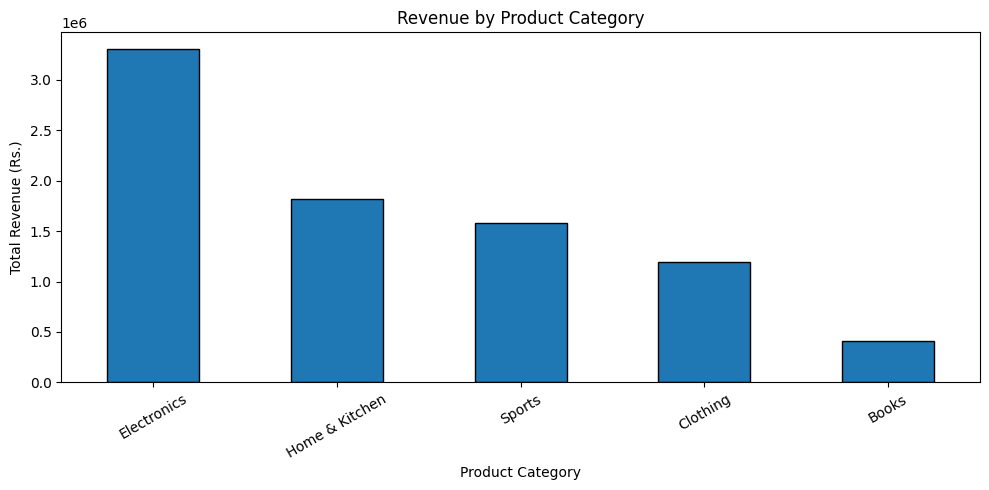

In [7]:
# Calculate revenue for each category
category_sales = (
    df.groupby("Category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Category:")
display(category_sales.reset_index())

# Visualize category revenue
plt.figure(figsize=(10, 5))
category_sales.plot(kind="bar", edgecolor="black")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (Rs.)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Monthly Sales Revenue:


,Month,Revenue
0,1,684750.77
1,2,506887.48
2,3,658886.92
3,4,598235.67
4,5,769024.89
5,6,650018.63
6,7,747756.36
7,8,719142.16
8,9,682726.85
9,10,754170.67


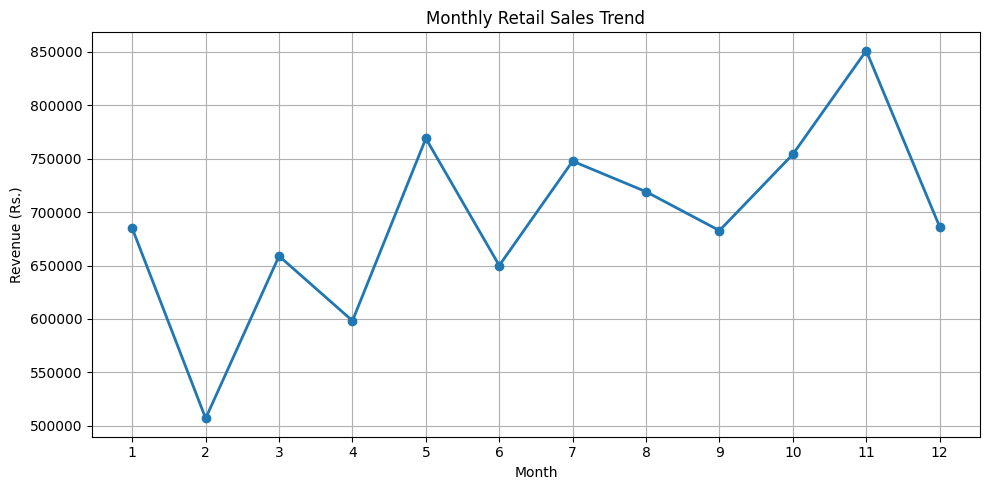

In [8]:
# Extract month from the order date
df["Month"] = df["Order_Date"].dt.month

monthly_sales = (
    df.groupby("Month")["Revenue"]
    .sum()
)

print("Monthly Sales Revenue:")
display(monthly_sales.reset_index())

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (Rs.)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

Revenue by Region:


,Region,Revenue
0,South,2256929.75
1,North,2132871.90
2,West,2042733.77
3,East,1876637.28


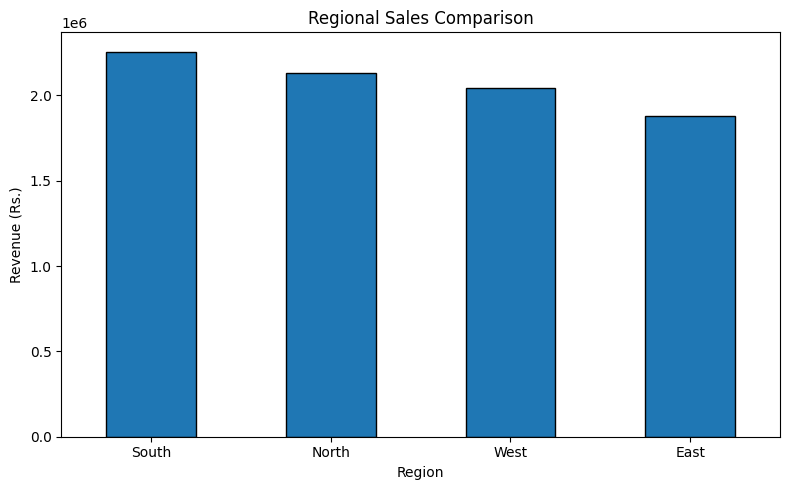

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [9]:
region_sales = (
    df.groupby("Region")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Region:")
display(region_sales.reset_index())

plt.figure(figsize=(8, 5))
region_sales.plot(kind="bar", edgecolor="black")

plt.title("Regional Sales Comparison")
plt.xlabel("Region")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Top 10 Products by Revenue:


,Product,Revenue
0,Headphones,1076963.45
1,Speaker,834066.46
2,Keyboard,728760.72
3,Smartwatch,664473.01
4,Cookware,560427.13
5,Mixer,500164.97
6,Yoga Mat,416742.32
7,Badminton Set,398783.47
8,Dumbbells,387060.12
9,Bedsheet,385186.25


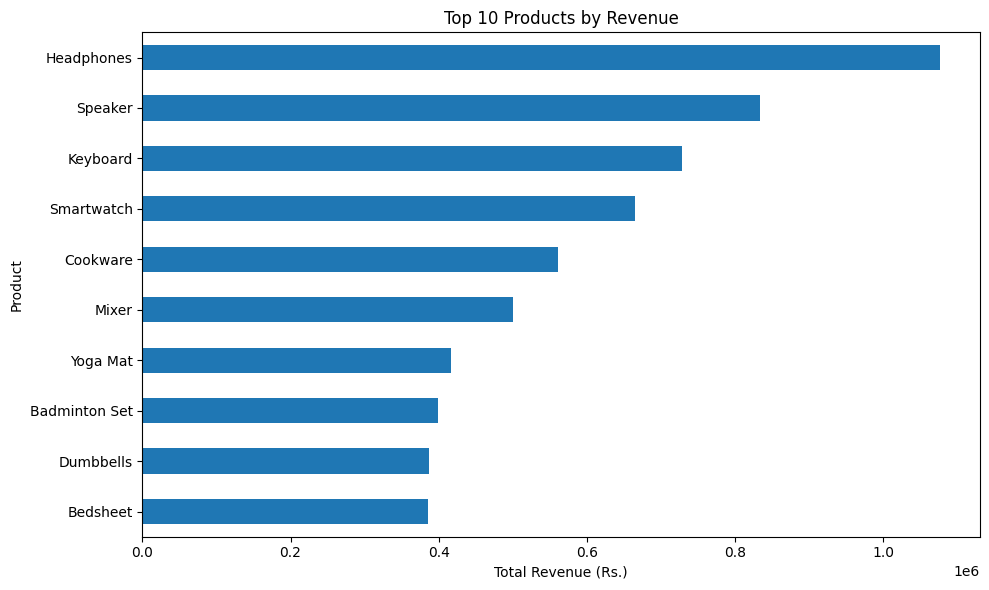

In [10]:
top_products = (
    df.groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_products.reset_index())

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (Rs.)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [11]:
# Save cleaned dataset
df.to_csv("cleaned_retail_sales.csv", index=False)

# Save analysis summaries
category_sales.to_csv("category_sales.csv")
monthly_sales.to_csv("monthly_sales.csv")
region_sales.to_csv("region_sales.csv")
top_products.to_csv("top_products.csv")

print("All analysis files saved successfully!")

All analysis files saved successfully!


In [12]:
%pip install pyspark

In [13]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("RetailSalesBDA")
    .master("local[*]")
    .getOrCreate()
)

print("Spark started successfully!")
print("Spark version:", spark.version)

Spark started successfully!
Spark version: 4.0.4


In [15]:
print("Type of df:", type(df))
print("Type of spark:", type(spark))

Type of df: <class 'pandas.core.frame.DataFrame'>
Type of spark: <class 'pyspark.sql.session.SparkSession'>


In [17]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1200

categories = ["Electronics", "Clothing", "Home & Kitchen", "Books", "Sports"]

products = {
    "Electronics": ["Headphones", "Keyboard", "Smartwatch", "Speaker"],
    "Clothing": ["T-shirt", "Jeans", "Jacket", "Sneakers"],
    "Home & Kitchen": ["Mixer", "Cookware", "Bedsheet", "Lamp"],
    "Books": ["Fiction Book", "Textbook", "Notebook", "Biography"],
    "Sports": ["Yoga Mat", "Football", "Dumbbells", "Badminton Set"]
}

category = np.random.choice(categories, n)
product = [np.random.choice(products[c]) for c in category]

price_ranges = {
    "Electronics": (700, 9000),
    "Clothing": (300, 3500),
    "Home & Kitchen": (250, 6000),
    "Books": (100, 1200),
    "Sports": (250, 4500)
}

price = [
    round(np.random.uniform(*price_ranges[c]), 2)
    for c in category
]

sales_pd = pd.DataFrame({
    "Order_ID": [f"ORD{i:05d}" for i in range(1, n + 1)],
    "Category": category,
    "Product": product,
    "Quantity": np.random.randint(1, 6, n),
    "Unit_Price": price,
    "Discount": np.random.choice(
        [0, 0.05, 0.10, 0.15, 0.20], n
    ),
    "Region": np.random.choice(
        ["North", "South", "East", "West"], n
    ),
    "Order_Date": np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"), n
    )
})

sales_pd["Revenue"] = (
    sales_pd["Quantity"]
    * sales_pd["Unit_Price"]
    * (1 - sales_pd["Discount"])
).round(2)

print("Dataset type:", type(sales_pd))
print("Dataset shape:", sales_pd.shape)

display(sales_pd.head())

Dataset type: <class 'pandas.core.frame.DataFrame'>
Dataset shape: (1200, 9)


,Order_ID,Category,Product,Quantity,Unit_Price,Discount,Region,Order_Date,Revenue
0,ORD00001,Books,Textbook,1,292.25,0.00,West,2025-09-19,292.25
1,ORD00002,Sports,Badminton Set,1,1783.28,0.05,South,2025-11-09,1694.12
2,ORD00003,Home & Kitchen,Cookware,2,5458.87,0.10,South,2025-03-12,9825.97
3,ORD00004,Sports,Badminton Set,2,3522.26,0.05,West,2025-08-07,6692.29
4,ORD00005,Sports,Football,1,2615.71,0.05,North,2025-01-21,2484.92


In [19]:
sales_pd.to_csv("/content/retail_sales_data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [20]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import to_date, col

spark = (
    SparkSession.builder
    .appName("RetailSalesBDA")
    .master("local[*]")
    .getOrCreate()
)

spark_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("/content/retail_sales_data.csv")
)

# Convert Order_Date to a proper date type
spark_df = spark_df.withColumn(
    "Order_Date",
    to_date(col("Order_Date"))
)

print("Spark CSV loading successful!")
print("Total records:", spark_df.count())

spark_df.printSchema()
spark_df.show(5, truncate=False)

Spark CSV loading successful!
Total records: 1200
root
 |-- Order_ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Product: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Unit_Price: double (nullable = true)
 |-- Discount: double (nullable = true)
 |-- Region: string (nullable = true)
 |-- Order_Date: date (nullable = true)
 |-- Revenue: double (nullable = true)

+--------+--------------+-------------+--------+----------+--------+------+----------+-------+
|Order_ID|Category      |Product      |Quantity|Unit_Price|Discount|Region|Order_Date|Revenue|
+--------+--------------+-------------+--------+----------+--------+------+----------+-------+
|ORD00001|Books         |Textbook     |1       |292.25    |0.0     |West  |2025-09-19|292.25 |
|ORD00002|Sports        |Badminton Set|1       |1783.28   |0.05    |South |2025-11-09|1694.12|
|ORD00003|Home & Kitchen|Cookware     |2       |5458.87   |0.1     |South |2025-03-12|9825.97|
|ORD00004|Sport

In [21]:
from pyspark.sql.functions import sum, avg, count

category_analysis = (
    spark_df
    .groupBy("Category")
    .agg(
        sum("Revenue").alias("Total_Revenue"),
        avg("Revenue").alias("Average_Revenue"),
        count("*").alias("Transactions")
    )
    .orderBy("Total_Revenue", ascending=False)
)

category_analysis.show(truncate=False)

+--------------+------------------+------------------+------------+
|Category      |Total_Revenue     |Average_Revenue   |Transactions|
+--------------+------------------+------------------+------------+
|Electronics   |3304263.6399999997|12957.896627450978|255         |
|Home & Kitchen|1818345.109999999 |8010.330881057264 |227         |
|Sports        |1583473.3799999992|6463.156653061221 |245         |
|Clothing      |1191452.6200000008|5113.530557939917 |233         |
|Books         |411637.9500000002 |1715.1581250000008|240         |
+--------------+------------------+------------------+------------+



In [22]:
from pyspark.sql.functions import sum, month

monthly_analysis = (
    spark_df
    .withColumn("Month", month("Order_Date"))
    .groupBy("Month")
    .agg(sum("Revenue").alias("Total_Revenue"))
    .orderBy("Month")
)

monthly_analysis.show(12)

+-----+-----------------+
|Month|    Total_Revenue|
+-----+-----------------+
|    1|684750.7700000001|
|    2|        506887.48|
|    3|658886.9199999999|
|    4|598235.6700000003|
|    5|769024.8900000001|
|    6|650018.6299999999|
|    7|        747756.36|
|    8|        719142.16|
|    9|682726.8500000001|
|   10|754170.6699999999|
|   11|851187.7199999999|
|   12|686384.5799999998|
+-----+-----------------+



In [23]:
region_analysis = (
    spark_df
    .groupBy("Region")
    .agg(
        sum("Revenue").alias("Total_Revenue")
    )
    .orderBy("Total_Revenue", ascending=False)
)

region_analysis.show()

+------+------------------+
|Region|     Total_Revenue|
+------+------------------+
| South|        2256929.75|
| North| 2132871.900000001|
|  West| 2042733.769999999|
|  East|1876637.2799999989|
+------+------------------+



In [24]:
from pyspark.sql.functions import countDistinct

spark_df.select(
    sum("Revenue").alias("Total_Revenue"),
    countDistinct("Order_ID").alias("Total_Orders"),
    sum("Quantity").alias("Units_Sold")
).show()

+-----------------+------------+----------+
|    Total_Revenue|Total_Orders|Units_Sold|
+-----------------+------------+----------+
|8309172.699999988|        1200|      3594|
+-----------------+------------+----------+



In [25]:
category_analysis.toPandas().to_csv(
    "/content/spark_category_results.csv", index=False
)

monthly_analysis.toPandas().to_csv(
    "/content/spark_monthly_results.csv", index=False
)

region_analysis.toPandas().to_csv(
    "/content/spark_region_results.csv", index=False
)

print("Spark analysis results saved successfully!")

Spark analysis results saved successfully!
